In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
import os

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]



path = '../../DESRES_NATIVE_DATA/BPTI/'

In [23]:
# Calculation of chi1 angles - uncomment to run
'''
topology_file = "protein.pdb"   
# residue numbers as they appear in the PDB/GRO
residue_ids = [14, 38]          # residues Cys14 and Cys38

out_file = "chi1_res14_res38.npy"

# -----------------------------
# Find trajectories
# ----------------------------
trajs = sorted(find_xtc_filenames(path))

# -----------------------------
# Helper: convert residue number to mdtraj residue index
# -----------------------------
top = md.load_topology(path+topology_file)

resid_to_index = {}
for res in top.residues:
    # mdtraj uses res.resSeq for the residue number in the PDB/GRO
    resid_to_index[res.resSeq] = res.index

residue_indices = [resid_to_index[r] for r in residue_ids]

# -----------------------------
# Loop over trajectories
# -----------------------------
all_chi1 = []

for xtc in trajs:
    print(f"Loading {xtc}")

    traj = md.load(path+xtc, top=path+topology_file)

    # chi1_angles shape: (n_frames, n_chi1)
    # chi1_indices tells which atoms define each chi1
    chi1_indices, chi1_angles = md.compute_chi1(traj)

    # Match chi1 angles to desired residues
    chi1_for_this_traj = []

    for res_idx in residue_indices:
        match = []

        for i, atom_quad in enumerate(chi1_indices):
            # all four atoms should belong to the same residue
            atom_residue = traj.topology.atom(atom_quad[0]).residue.index

            if atom_residue == res_idx:
                match.append(i)

        if len(match) == 0:
            raise ValueError(f"No chi1 found for residue index {res_idx} in {xtc}")

        if len(match) > 1:
            raise ValueError(f"Multiple chi1 matches for residue index {res_idx} in {xtc}")

        chi1_for_this_traj.append(chi1_angles[:, match[0]])

    # shape: (n_frames, n_selected_residues)
    chi1_for_this_traj = np.column_stack(chi1_for_this_traj)

    all_chi1.append(chi1_for_this_traj)

# -----------------------------
# Concatenate and save
# -----------------------------
all_chi1 = np.concatenate(all_chi1, axis=0)

np.save(out_file, all_chi1)

print(f"Saved {all_chi1.shape} array to {out_file}")
'''

'\ntopology_file = "protein.pdb"   \n# residue numbers as they appear in the PDB/GRO\nresidue_ids = [14, 38]          # residues Cys14 and Cys38\n\nout_file = "chi1_res14_res38.npy"\n\n# -----------------------------\n# Find trajectories\n# ----------------------------\ntrajs = sorted(find_xtc_filenames(path))\n\n# -----------------------------\n# Helper: convert residue number to mdtraj residue index\n# -----------------------------\ntop = md.load_topology(path+topology_file)\n\nresid_to_index = {}\nfor res in top.residues:\n    # mdtraj uses res.resSeq for the residue number in the PDB/GRO\n    resid_to_index[res.resSeq] = res.index\n\nresidue_indices = [resid_to_index[r] for r in residue_ids]\n\n# -----------------------------\n# Loop over trajectories\n# -----------------------------\nall_chi1 = []\n\nfor xtc in trajs:\n    print(f"Loading {xtc}")\n\n    traj = md.load(path+xtc, top=path+topology_file)\n\n    # chi1_angles shape: (n_frames, n_chi1)\n    # chi1_indices tells which a

In [4]:
# load chi1 angles
cys14_chi1 = np.degrees(np.load('chi1_res14_res38.npy')[:,0])
cys38_chi1 = np.degrees(np.load('chi1_res14_res38.npy')[:,1])
print("Cys14 chi1 range:", cys14_chi1.min(), cys14_chi1.max())
print("Cys38 chi1 range:", cys38_chi1.min(), cys38_chi1.max())
print("n frames:", len(cys14_chi1))

Cys14 chi1 range: -179.99974 179.99974
Cys38 chi1 range: -179.99767 179.9997
n frames: 4124963


Prior populations:
g-/g-   0.0666
g-/g+   0.3491
g-/t    0.0006
g+/g-   0.0083
g+/g+   0.5032
g+/t    0.0014
t/g-    0.0506
t/g+    0.0183
t/t     0.0018

Main states:
g-/g-   0.0666
g-/g+   0.3491
g+/g+   0.5032
t/g-    0.0506


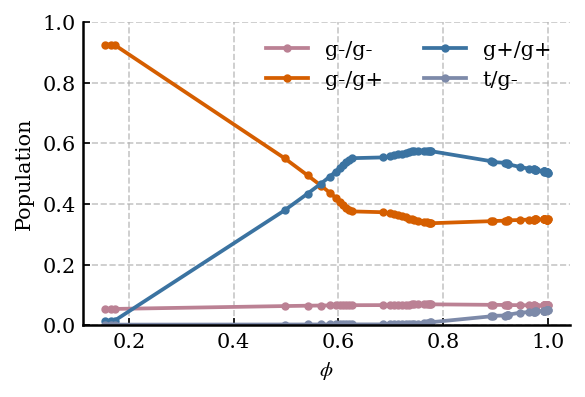

In [5]:
# posterior weights: shape (n_reweighting_points, n_frames)
wopts = np.load(path + '/rewM14DH_scaled/log_lambda_wopt_array.npy')

rewdata = np.loadtxt(path + '/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
stats = pd.read_csv(path + '/rewM14DH_scaled/log_lambda_stats_df.csv')
chi2 = rewdata[0,:]
phi = rewdata[1,:]
thetas = rewdata[2,:]

assert len(cys14_chi1) == len(cys38_chi1)
assert wopts.shape[1] == len(cys14_chi1)

# canonical chi1 rotamers
rotamer_centers = {"g-": -60.0, "g+": 60.0, "t": 180.0}

def angular_distance(a, b):
    return np.abs((a - b + 180.0) % 360.0 - 180.0)

def assign_rotamer(angle):
    distances = {name: angular_distance(angle, center) for name, center in rotamer_centers.items()}
    return min(distances, key=distances.get)

# assign each frame to a chi1(14)/chi1(38) rotamer combination
rot14 = np.array([assign_rotamer(x) for x in cys14_chi1])
rot38 = np.array([assign_rotamer(x) for x in cys38_chi1])
state_labels = np.array([f"{a}/{b}" for a, b in zip(rot14, rot38)])

# all possible states
states = [f"{a}/{b}" for a in ["g-", "g+", "t"] for b in ["g-", "g+", "t"]]

# prior populations
prior_population = {state: np.mean(state_labels == state) for state in states}

print("Prior populations:")
for state in states:
    print(f"{state:7s} {prior_population[state]:.4f}")

# only keep states with prior population > 0.05
main_states = [state for state in states if prior_population[state] > 0.05]

print("\nMain states:")
for state in main_states:
    print(f"{state:7s} {prior_population[state]:.4f}")

# weighted populations for every posterior
populations = np.zeros((len(wopts), len(states)))

for i, w in enumerate(wopts):
    w = np.asarray(w, dtype=float)
    w = w / np.sum(w)

    for j, state in enumerate(states):
        populations[i, j] = np.sum(w[state_labels == state])

# dataframe
pop_df = pd.DataFrame(populations, columns=states)
pop_df.insert(0, "phi", phi)

# colors in line with previous plots
state_colors = {
    "g-/g+": "#D55E00",
    "g+/g+": "#3B73A1",
    "g-/g-": "#BB8194",
    "g+/g-": "#D9D9D9",
    "g-/t":  "#A97F90",
    "g+/t":  "#C9B2BB",
    "t/g-":  "#7D8AA9",
    "t/g+":  "#9FB3C8",
    "t/t":   "#BDBDBD"
}

# plot
fig, ax = plt.subplots(figsize=(4.00, 2.75))

for state in main_states:
    ax.plot(pop_df["phi"].to_numpy(), pop_df[state].to_numpy(), marker="o", ms=3, lw=1.8, color=state_colors[state], label=state)

ax.set_xlabel(r"$\phi$")
ax.set_ylabel("Population")
ax.set_ylim(0, 1)
ax.legend(frameon=False, ncol=2)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(top=False, right=False)

plt.tight_layout()
plt.savefig('disulfide_rotamer_populations.pdf')
plt.show()

In [28]:
# PDB files of main dihedral rotamer states

import os

# ------------------------------------------------------------
# Settings
# ------------------------------------------------------------

target_phi = 0.5
n_structures = 10
topology_file = "protein.pdb"
outdir = "./disulfide_state_structures_phi05"

os.makedirs(outdir, exist_ok=True)

# posterior closest to phi = 0.5
post_idx = np.argmin(np.abs(phi - target_phi))
w_post = np.asarray(wopts[post_idx], dtype=float)
w_post = w_post / np.sum(w_post)

print(f"Using posterior index {post_idx}, phi = {phi[post_idx]:.4f}")

# ------------------------------------------------------------
# Main states: prior population > 0.05
# ------------------------------------------------------------

main_states = [state for state in states if prior_population[state] > 0.05]

print("\nMain states:")
for state in main_states:
    print(f"{state}: prior population = {prior_population[state]:.4f}")

# ------------------------------------------------------------
# Get trajectory frame ranges
# must use exactly the same trajectory order as chi1 calculation
# ------------------------------------------------------------

trajs = sorted(find_xtc_filenames(path))

traj_nframes = []

for xtc in trajs:
    with md.open(path + xtc) as f:
        traj_nframes.append(len(f))

traj_nframes = np.asarray(traj_nframes, dtype=int)
traj_starts = np.concatenate(([0], np.cumsum(traj_nframes)[:-1]))
traj_ends = np.cumsum(traj_nframes)

print(f"\nFrames from trajectories: {traj_nframes.sum()}")
print(f"Frames in chi1 arrays:     {len(state_labels)}")

assert traj_nframes.sum() == len(state_labels), "Trajectory frame count does not match chi1/state arrays"

# ------------------------------------------------------------
# Helper: global frame -> trajectory + local frame
# ------------------------------------------------------------

def global_to_local(global_idx):
    traj_idx = np.searchsorted(traj_ends, global_idx, side="right")
    local_idx = global_idx - traj_starts[traj_idx]
    return traj_idx, local_idx

# ------------------------------------------------------------
# Find 10 frames closest to each state's canonical chi1 values
# and then order those selected frames by posterior weight
# ------------------------------------------------------------

metadata = []

for state in main_states:

    rot14_name, rot38_name = state.split("/")

    target14 = rotamer_centers[rot14_name]
    target38 = rotamer_centers[rot38_name]

    mask = state_labels == state
    frame_indices = np.where(mask)[0]

    # angular distances from canonical rotamer centers
    d14 = angular_distance(cys14_chi1[frame_indices], target14)
    d38 = angular_distance(cys38_chi1[frame_indices], target38)

    # RMS distance in the 2D chi1 space
    distance = np.sqrt((d14**2 + d38**2) / 2.0)

    # select the 10 closest frames
    closest_order = np.argsort(distance)[:n_structures]
    selected_frames = frame_indices[closest_order]
    selected_distances = distance[closest_order]

    # sort those 10 by posterior weight, highest first
    weight_order = np.argsort(w_post[selected_frames])[::-1]
    selected_frames = selected_frames[weight_order]
    selected_distances = selected_distances[weight_order]

    state_dir = os.path.join(outdir, state.replace("/", "_"))
    os.makedirs(state_dir, exist_ok=True)

    print(f"\nState {state}")
    print(f"Target chi1: Cys14 = {target14:.1f}, Cys38 = {target38:.1f}")

    for rank, (global_idx, dist) in enumerate(zip(selected_frames, selected_distances), start=1):

        traj_idx, local_idx = global_to_local(global_idx)
        xtc = trajs[traj_idx]

        frame = md.load_frame(path + xtc, index=int(local_idx), top=path + topology_file)

        weight = w_post[global_idx]
        chi14 = cys14_chi1[global_idx]
        chi38 = cys38_chi1[global_idx]

        outfile = os.path.join(state_dir, f"{state.replace('/', '_')}_rank{rank:02d}.pdb")
        frame.save_pdb(outfile)

        metadata.append({
            "state": state,
            "rank_by_posterior_weight": rank,
            "global_frame": global_idx,
            "trajectory": xtc,
            "local_frame": local_idx,
            "chi1_Cys14": chi14,
            "chi1_Cys38": chi38,
            "dihedral_distance": dist,
            "posterior_weight": weight,
            "phi": phi[post_idx],
            "p_prior_state": prior_population[state]
        })

        print(f"{rank:2d}  frame={global_idx:8d}  traj={xtc}  local={local_idx:7d}  chi14={chi14:7.2f}  chi38={chi38:7.2f}  dist={dist:6.2f}  weight={weight:.3e}")

# ------------------------------------------------------------
# Save metadata
# ------------------------------------------------------------

metadata_df = pd.DataFrame(metadata)
metadata_df.to_csv(os.path.join(outdir, "selected_structures.csv"), index=False)

print(f"\nSaved structures and metadata to:")
print(outdir)

Using posterior index 48, phi = 0.4972

Main states:
g-/g-: prior population = 0.0666
g-/g+: prior population = 0.3491
g+/g+: prior population = 0.5032
t/g-: prior population = 0.0506

Frames from trajectories: 4124963
Frames in chi1 arrays:     4124963

State g-/g-
Target chi1: Cys14 = -60.0, Cys38 = -60.0
 1  frame= 3405272  traj=bpti-protein-340.xtc  local=   5272  chi14= -60.07  chi38= -60.11  dist=  0.09  weight=4.100e-07
 2  frame= 3806517  traj=bpti-protein-380.xtc  local=   6517  chi14= -60.05  chi38= -59.98  dist=  0.04  weight=3.965e-07
 3  frame=  936178  traj=bpti-protein-093.xtc  local=   6178  chi14= -60.02  chi38= -60.01  dist=  0.01  weight=2.532e-07
 4  frame= 3443831  traj=bpti-protein-344.xtc  local=   3831  chi14= -60.00  chi38= -60.08  dist=  0.05  weight=2.345e-07
 5  frame= 1511001  traj=bpti-protein-151.xtc  local=   1001  chi14= -59.94  chi38= -60.11  dist=  0.09  weight=2.068e-07
 6  frame= 2229142  traj=bpti-protein-222.xtc  local=   9142  chi14= -59.90  chi3

Main prior states:
g-/g-: 0.0666
g-/g+: 0.3491
g+/g+: 0.5032
t/g-: 0.0506
g-/g-: 274802 frames, population = 0.0666


/tmp/ipykernel_1212233/372500465.py:40: RuntimeWarning: divide by zero encountered in divide
  PF = 1.0 / fopen


g-/g+: 1440228 frames, population = 0.3491
g+/g+: 2075549 frames, population = 0.5032
t/g-: 208861 frames, population = 0.0506


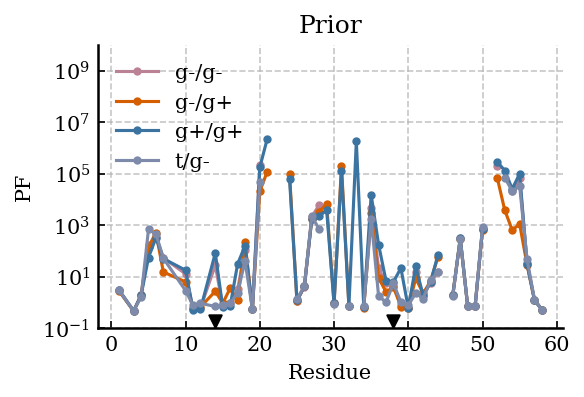

In [39]:
# load open-state matrix and residue numbers
O = np.load(path + '/rewM14DH_scaled/O.npy')
residues = np.loadtxt(path + '/rewM14DH_scaled/amideresidues.txt').astype(int)

assert O.shape[0] == len(state_labels)

# prior state populations
state_counts = {state: np.mean(state_labels == state) for state in states}

# keep states with prior population > 0.05
main_states = [state for state in states if state_counts[state] > 0.05]

print("Main prior states:")
for state in main_states:
    print(f"{state}: {state_counts[state]:.4f}")

# same colours as population plot
state_colors = {
    "g-/g+": "#D55E00",
    "g+/g+": "#3B73A1",
    "g-/g-": "#BB8194",
    "g+/g-": "#D9D9D9",
    "g-/t":  "#A97F90",
    "g+/t":  "#C9B2BB",
    "t/g-":  "#7D8AA9",
    "t/g+":  "#9FB3C8",
    "t/t":   "#BDBDBD"
}

# calculate per-state PFs
state_PFs = {}
state_fopen = {}
state_masks = {}

for state in main_states:
    mask = state_labels == state
    state_masks[state] = mask

    fopen = np.mean(O[mask], axis=0)
    PF = 1.0 / fopen

    state_fopen[state] = fopen
    state_PFs[state] = PF

    print(f"{state}: {np.sum(mask)} frames, population = {np.mean(mask):.4f}")

# plot PF profiles
fig, ax = plt.subplots(figsize=(4, 2.75))

for state in main_states:
    ax.plot(residues, state_PFs[state], marker="o", ms=3, lw=1.5, color=state_colors[state], label=state)

ax.set_yscale("log")
ax.set_xlabel("Residue")
ax.set_ylabel("PF")
ax.set_title('Prior')
ax.legend(frameon=False)
ax.set_ylim(1e-1,1e10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

# mark disulfide residues near the bottom of the plot
for r in [14, 38]:
    ax.scatter(r, 2e-1, marker="v", s=35, color="black", zorder=5)

plt.tight_layout()
plt.savefig('rotamer_states_prior_PF.pdf')
plt.show()

Main prior states:
g-/g-: 0.0666
g-/g+: 0.3491
g+/g+: 0.5032
t/g-: 0.0506

Using posterior index 48, phi = 0.4972
g-/g-: posterior population = 0.0637


/tmp/ipykernel_1212233/3666321149.py:52: RuntimeWarning: divide by zero encountered in divide
  PF = 1.0 / fopen


g-/g+: posterior population = 0.5509
g+/g+: posterior population = 0.3792
t/g-: posterior population = 0.0028


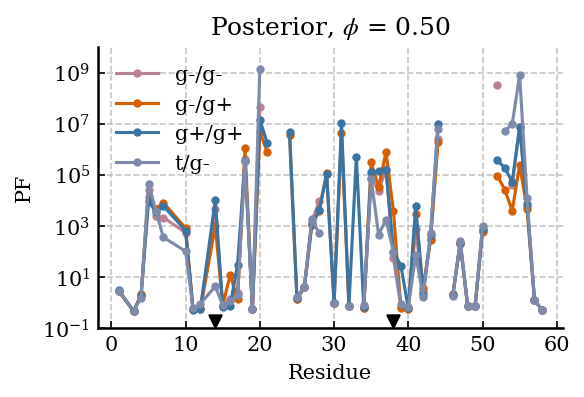

In [38]:
# load open-state matrix and residue numbers
O = np.load(path + '/rewM14DH_scaled/O.npy')
residues = np.loadtxt(path + '/rewM14DH_scaled/amideresidues.txt').astype(int)

assert O.shape[0] == len(state_labels)

# prior state populations
state_counts = {state: np.mean(state_labels == state) for state in states}

# keep states with prior population > 0.05
main_states = [state for state in states if state_counts[state] > 0.05]

print("Main prior states:")
for state in main_states:
    print(f"{state}: {state_counts[state]:.4f}")

# same colours as population plot
state_colors = {
    "g-/g+": "#D55E00",
    "g+/g+": "#3B73A1",
    "g-/g-": "#BB8194",
    "g+/g-": "#D9D9D9",
    "g-/t":  "#A97F90",
    "g+/t":  "#C9B2BB",
    "t/g-":  "#7D8AA9",
    "t/g+":  "#9FB3C8",
    "t/t":   "#BDBDBD"
}

# choose posterior closest to phi = 0.5
target_phi = 0.5
post_idx = np.argmin(np.abs(phi - target_phi))
w = np.asarray(wopts[post_idx], dtype=float)
w = w / np.sum(w)

print(f"\nUsing posterior index {post_idx}, phi = {phi[post_idx]:.4f}")

# calculate posterior per-state PFs
state_PFs = {}
state_fopen = {}
state_masks = {}

for state in main_states:
    mask = state_labels == state
    state_masks[state] = mask

    w_state = w[mask]
    state_population = np.sum(w_state)
    w_state = w_state / np.sum(w_state)

    fopen = np.average(O[mask], axis=0, weights=w_state)
    PF = 1.0 / fopen

    state_fopen[state] = fopen
    state_PFs[state] = PF

    print(f"{state}: posterior population = {state_population:.4f}")

# plot PF profiles
fig, ax = plt.subplots(figsize=(4, 2.75))

for state in main_states:
    ax.plot(residues, state_PFs[state], marker="o", ms=3, lw=1.5, color=state_colors[state], label=state)

ax.set_yscale("log")
ax.set_xlabel("Residue")
ax.set_ylabel("PF")
ax.set_title(rf'Posterior, $\phi$ = {phi[post_idx]:.2f}')
ax.legend(frameon=False)
ax.set_ylim(1e-1,1e10)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

# mark disulfide residues near the bottom of the plot
for r in [14, 38]:
    ax.scatter(r, 2e-1, marker="v", s=35, color="black", zorder=5)

plt.tight_layout()
plt.savefig('rotamer_states_posterior_phi05_PF.pdf')
plt.show()

Posterior 1 phi = 0.7730
Posterior phi~0.5 = 0.4972
Posterior 2 phi = 0.1543


/tmp/ipykernel_2210638/1320289685.py:36: RuntimeWarning: divide by zero encountered in divide
  PFprior = 1 / np.mean(fopen, axis=0)
/tmp/ipykernel_2210638/1320289685.py:37: RuntimeWarning: divide by zero encountered in divide
  PF1 = 1 / np.average(fopen, weights=wopt1, axis=0)
/tmp/ipykernel_2210638/1320289685.py:38: RuntimeWarning: divide by zero encountered in divide
  PF05 = 1 / np.average(fopen, weights=wopt05, axis=0)
/tmp/ipykernel_2210638/1320289685.py:39: RuntimeWarning: divide by zero encountered in divide
  PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)


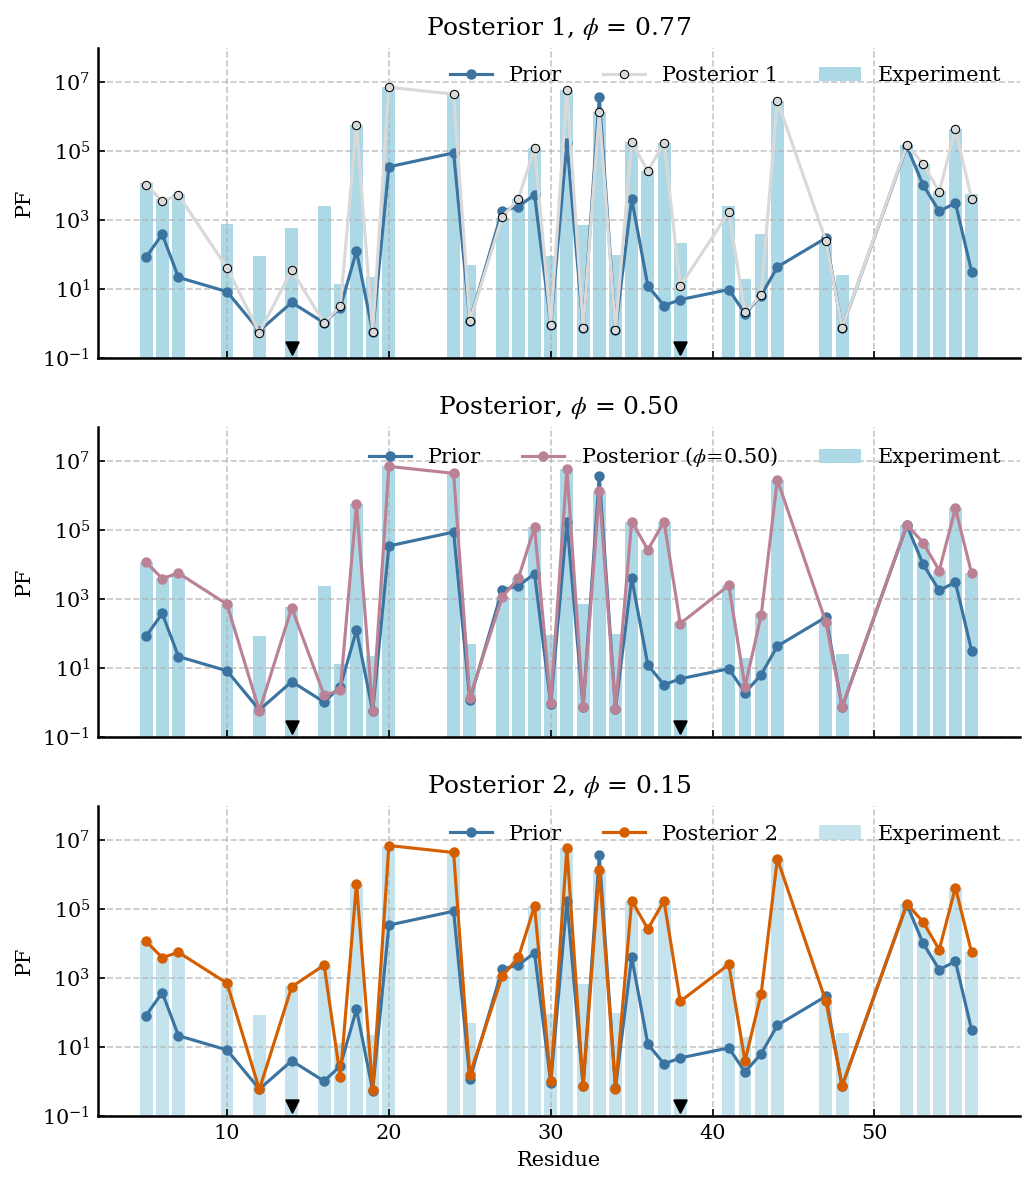

In [7]:
exp = pd.read_csv('../../EXP_DATA/PF_Nguyen_2018/BPTI.csv')

# get fopen
fopen = np.load('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/O.npy')
res = np.loadtxt('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/amideresidues.txt').astype(int)
exp_residues = np.loadtxt('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/exp_residues.txt').astype(int)

# indices corresponding to the same common residue set
exp_idxs_comp = np.array([list(res).index(ele) for ele in exp_residues])
exp_idxs_exp = np.array([list(exp['Model_residue']).index(ele) for ele in exp_residues])

# reweighting data
wopt_array = np.load('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

# posterior 1 = elbow
wopt1 = np.load('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# posterior closest to phi = 0.5
idx_phi05 = np.argmin(np.abs(phi - 0.5))
wopt05 = wopt_array[idx_phi05]

# posterior 2 = final
wopt2 = np.load('../../DESRES_NATIVE_DATA/BPTI/rewM14DH_scaled/log_lambda_wopt.npy')

# identify phi values
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1 phi = {phi[idx_post1]:.4f}")
print(f"Posterior phi~0.5 = {phi[idx_phi05]:.4f}")
print(f"Posterior 2 phi = {phi[idx_post2]:.4f}")

# PFs for all computed amide residues
PFprior = 1 / np.mean(fopen, axis=0)
PF1 = 1 / np.average(fopen, weights=wopt1, axis=0)
PF05 = 1 / np.average(fopen, weights=wopt05, axis=0)
PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)

# select the common experimental residues in exactly the same order
plot_res = exp_residues
PFexp = exp['PF'].to_numpy()[exp_idxs_exp]
PFprior_plot = PFprior[exp_idxs_comp]
PF1_plot = PF1[exp_idxs_comp]
PF05_plot = PF05[exp_idxs_comp]
PF2_plot = PF2[exp_idxs_comp]

# colours
COLOR_PRIOR = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST05 = "#BB8194"
COLOR_POST2 = "#D55E00"
COLOR_EXP = "lightblue"

# plot
fig, axes = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

# ------------------------------------------------------------
# Posterior 1
# ------------------------------------------------------------
ax = axes[0]

ax.bar(plot_res, PFexp, width=0.8, color=COLOR_EXP, edgecolor="none", label="Experiment", zorder=1)
ax.plot(plot_res, PFprior_plot, "-o", color=COLOR_PRIOR, markersize=4, linewidth=1.5, label="Prior", zorder=3)
ax.plot(plot_res, PF1_plot, "-o", color=COLOR_POST1, markeredgecolor="black", markeredgewidth=0.5, markersize=4, linewidth=1.5, label="Posterior 1", zorder=4)

ax.set_yscale("log")
ax.set_ylabel("PF")
ax.set_ylim(1e-1,1e8)
ax.set_title(rf"Posterior 1, $\phi$ = {phi[idx_post1]:.2f}")
ax.legend(frameon=False, ncol=3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

# mark disulfide residues near the bottom of the plot
for r in [14, 38]:
    ax.scatter(r, 2e-1, marker="v", s=35, color="black", zorder=5)

# ------------------------------------------------------------
# Posterior closest to phi = 0.5
# ------------------------------------------------------------
ax = axes[1]

ax.bar(plot_res, PFexp, width=0.8, color=COLOR_EXP, edgecolor="none", label="Experiment", zorder=1)
ax.plot(plot_res, PFprior_plot, "-o", color=COLOR_PRIOR, markersize=4, linewidth=1.5, label="Prior", zorder=3)
ax.plot(plot_res, PF05_plot, "-o", color=COLOR_POST05, markersize=4, linewidth=1.5, label=rf"Posterior ($\phi$={phi[idx_phi05]:.2f})", zorder=4)

ax.set_yscale("log")
ax.set_ylabel("PF")
ax.set_ylim(1e-1,1e8)
ax.set_title(rf"Posterior, $\phi$ = {phi[idx_phi05]:.2f}")
ax.legend(frameon=False, ncol=3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

# mark disulfide residues near the bottom of the plot
for r in [14, 38]:
    ax.scatter(r, 2e-1, marker="v", s=35, color="black", zorder=5)

# ------------------------------------------------------------
# Posterior 2
# ------------------------------------------------------------
ax = axes[2]

ax.bar(plot_res, PFexp, width=0.8, color=COLOR_EXP, edgecolor="none", label="Experiment", zorder=1, alpha=0.7)
ax.plot(plot_res, PFprior_plot, "-o", color=COLOR_PRIOR, markersize=4, linewidth=1.5, label="Prior", zorder=3)
ax.plot(plot_res, PF2_plot, "-o", color=COLOR_POST2, markersize=4, linewidth=1.5, label="Posterior 2", zorder=4)

ax.set_yscale("log")
ax.set_xlabel("Residue")
ax.set_ylabel("PF")
ax.set_ylim(1e-1,1e8)
ax.set_title(rf"Posterior 2, $\phi$ = {phi[idx_post2]:.2f}")
ax.legend(frameon=False, ncol=3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

# mark disulfide residues near the bottom of the plot
for r in [14, 38]:
    ax.scatter(r, 2e-1, marker="v", s=35, color="black", zorder=5)

plt.tight_layout()
plt.savefig('EXP_vs_CALC_PF.pdf')
plt.show()

Posterior 1: phi = 0.7730, chi2 = 29.7909
Posterior phi~0.5: phi = 0.4972, chi2 = 24.0723
Posterior 2: phi = 0.1543, chi2 = 18.0008


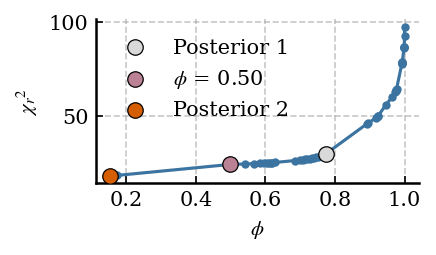

In [12]:
# chi2 vs phi

# identify the three posterior points
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_phi05 = np.argmin(np.abs(phi - 0.5))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1: phi = {phi[idx_post1]:.4f}, chi2 = {chi2[idx_post1]:.4f}")
print(f"Posterior phi~0.5: phi = {phi[idx_phi05]:.4f}, chi2 = {chi2[idx_phi05]:.4f}")
print(f"Posterior 2: phi = {phi[idx_post2]:.4f}, chi2 = {chi2[idx_post2]:.4f}")

# colours
COLOR_CURVE = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST05 = "#BB8194"
COLOR_POST2 = "#D55E00"

# sort by phi for a clean line
order = np.argsort(phi)

fig, ax = plt.subplots(figsize=(3, 1.8))

ax.plot(phi[order], chi2[order], "-o", color=COLOR_CURVE, markersize=3, linewidth=1.5, zorder=2)

# highlight selected posteriors
ax.scatter(phi[idx_post1], chi2[idx_post1], s=55, color=COLOR_POST1, edgecolor="black", linewidth=0.6, label="Posterior 1", zorder=4)
ax.scatter(phi[idx_phi05], chi2[idx_phi05], s=55, color=COLOR_POST05, edgecolor="black", linewidth=0.6, label=rf"$\phi$ = {phi[idx_phi05]:.2f}", zorder=4)
ax.scatter(phi[idx_post2], chi2[idx_post2], s=55, color=COLOR_POST2, edgecolor="black", linewidth=0.6, label="Posterior 2", zorder=4)

ax.set_xlabel(r"$\phi$")
ax.set_ylabel(r"$\chi$$_{r}$$^{2}$")
ax.legend(frameon=False)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig("chi2_vs_phi.pdf") 
plt.show()

Posterior 1 phi = 0.7730
Posterior 2 phi = 0.1543


/tmp/ipykernel_2210638/934958948.py:37: RuntimeWarning: divide by zero encountered in divide
  PFprior = 1 / np.mean(fopen, axis=0)
/tmp/ipykernel_2210638/934958948.py:38: RuntimeWarning: divide by zero encountered in divide
  PF1 = 1 / np.average(fopen, weights=wopt1, axis=0)
/tmp/ipykernel_2210638/934958948.py:39: RuntimeWarning: divide by zero encountered in divide
  PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)


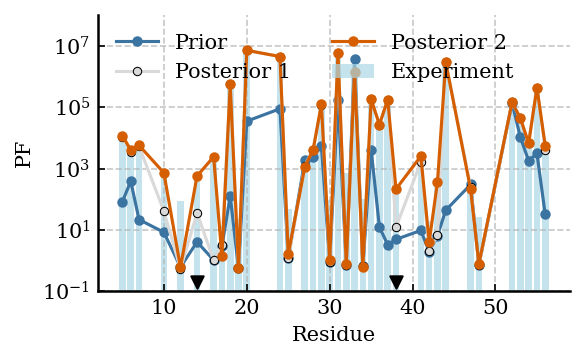

In [13]:
# predicted data overlaid

# comparison of NMR protection factors and prior/posterior

protein = 'BPTI'

exp = pd.read_csv(f'../../EXP_DATA/PF_Nguyen_2018/{protein}.csv')

# get fopen
fopen = np.load(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/O.npy')
res = np.loadtxt(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/amideresidues.txt').astype(int)
exp_residues = np.loadtxt(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/exp_residues.txt').astype(int)

# indices corresponding to the same common residue set
exp_idxs_comp = np.array([list(res).index(ele) for ele in exp_residues])
exp_idxs_exp = np.array([list(exp['Model_residue']).index(ele) for ele in exp_residues])

# reweighting data
wopt_array = np.load(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

# posterior 1 = elbow
wopt1 = np.load(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_elbow.npy')

# posterior 2 = final
wopt2 = np.load(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# identify phi values
idx_post1 = np.argmin(np.sum((wopt_array - wopt1[None,:])**2, axis=1))
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior 1 phi = {phi[idx_post1]:.4f}")
print(f"Posterior 2 phi = {phi[idx_post2]:.4f}")

# PFs for all computed amide residues
PFprior = 1 / np.mean(fopen, axis=0)
PF1 = 1 / np.average(fopen, weights=wopt1, axis=0)
PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)

# select the common experimental residues in exactly the same order
plot_res = exp_residues
PFexp = exp['PF'].to_numpy()[exp_idxs_exp]
PFprior_plot = PFprior[exp_idxs_comp]
PF1_plot = PF1[exp_idxs_comp]
PF2_plot = PF2[exp_idxs_comp]

# colours
COLOR_PRIOR = "#3B73A1"
COLOR_POST1 = "#D9D9D9"
COLOR_POST2 = "#D55E00"
COLOR_EXP = "lightblue"

# plot
fig, ax = plt.subplots(figsize=(4,2.5))

ax.bar(plot_res, PFexp, width=0.8, color=COLOR_EXP, edgecolor="none", alpha=0.7, label="Experiment", zorder=1)
ax.plot(plot_res, PFprior_plot, "-o", color=COLOR_PRIOR, markersize=4, linewidth=1.5, label="Prior", zorder=3)
ax.plot(plot_res, PF1_plot, "-o", color=COLOR_POST1, markeredgecolor="black", markeredgewidth=0.5, markersize=4, linewidth=1.5, label=rf"Posterior 1", zorder=4)
ax.plot(plot_res, PF2_plot, "-o", color=COLOR_POST2, markersize=4, linewidth=1.5, label=rf"Posterior 2", zorder=5)

ax.set_yscale("log")
ax.set_xlabel("Residue")
ax.set_ylabel("PF")
ax.set_ylim(1e-1, 1e8)
ax.legend(frameon=False, ncol=2)

# mark disulfide residues near the bottom of the plot
for r in [14, 38]:
    ax.scatter(r, 2e-1, marker="v", s=35, color="black", zorder=5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig('EXP_vs_CALC_PF_NMR.pdf')
plt.show()

Posterior phi~0.5 = 0.4972
Posterior 2 phi = 0.1543


/tmp/ipykernel_2210638/470312395.py:37: RuntimeWarning: divide by zero encountered in divide
  PFprior = 1 / np.mean(fopen, axis=0)
/tmp/ipykernel_2210638/470312395.py:38: RuntimeWarning: divide by zero encountered in divide
  PF05 = 1 / np.average(fopen, weights=wopt05, axis=0)
/tmp/ipykernel_2210638/470312395.py:39: RuntimeWarning: divide by zero encountered in divide
  PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)


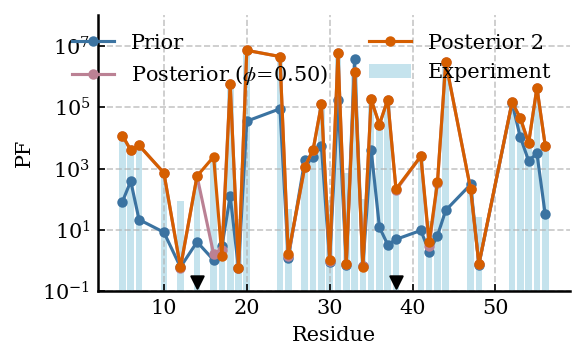

In [14]:
# predicted data overlaid

# comparison of NMR protection factors and prior/posterior

protein = 'BPTI'

exp = pd.read_csv(f'../../EXP_DATA/PF_Nguyen_2018/{protein}.csv')

# get fopen
fopen = np.load(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/O.npy')
res = np.loadtxt(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/amideresidues.txt').astype(int)
exp_residues = np.loadtxt(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/exp_residues.txt').astype(int)

# indices corresponding to the same common residue set
exp_idxs_comp = np.array([list(res).index(ele) for ele in exp_residues])
exp_idxs_exp = np.array([list(exp['Model_residue']).index(ele) for ele in exp_residues])

# reweighting data
wopt_array = np.load(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt_array.npy')
rewdata = np.loadtxt(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/log_lambda_reweighting_chi2_phi_theta.txt')
phi = rewdata[1,:]

# posterior closest to phi = 0.5
idx_phi05 = np.argmin(np.abs(phi - 0.5))
wopt05 = wopt_array[idx_phi05]

# posterior 2 = final
wopt2 = np.load(f'../../DESRES_NATIVE_DATA/{protein}/rewM14DH_scaled/log_lambda_wopt.npy')

# identify phi value of posterior 2
idx_post2 = np.argmin(np.sum((wopt_array - wopt2[None,:])**2, axis=1))

print(f"Posterior phi~0.5 = {phi[idx_phi05]:.4f}")
print(f"Posterior 2 phi = {phi[idx_post2]:.4f}")

# PFs for all computed amide residues
PFprior = 1 / np.mean(fopen, axis=0)
PF05 = 1 / np.average(fopen, weights=wopt05, axis=0)
PF2 = 1 / np.average(fopen, weights=wopt2, axis=0)

# select the common experimental residues in exactly the same order
plot_res = exp_residues
PFexp = exp['PF'].to_numpy()[exp_idxs_exp]
PFprior_plot = PFprior[exp_idxs_comp]
PF05_plot = PF05[exp_idxs_comp]
PF2_plot = PF2[exp_idxs_comp]

# colours
COLOR_PRIOR = "#3B73A1"
COLOR_POST05 = "#BB8194"
COLOR_POST2 = "#D55E00"
COLOR_EXP = "lightblue"

# plot
fig, ax = plt.subplots(figsize=(4,2.5))

ax.bar(plot_res, PFexp, width=0.8, color=COLOR_EXP, edgecolor="none", alpha=0.7, label="Experiment", zorder=1)
ax.plot(plot_res, PFprior_plot, "-o", color=COLOR_PRIOR, markersize=4, linewidth=1.5, label="Prior", zorder=3)
ax.plot(plot_res, PF05_plot, "-o", color=COLOR_POST05, markersize=4, linewidth=1.5, label=rf"Posterior ($\phi$={phi[idx_phi05]:.2f})", zorder=4)
ax.plot(plot_res, PF2_plot, "-o", color=COLOR_POST2, markersize=4, linewidth=1.5, label="Posterior 2", zorder=5)

ax.set_yscale("log")
ax.set_xlabel("Residue")
ax.set_ylabel("PF")
ax.set_ylim(1e-1, 1e8)
ax.legend(frameon=False, ncol=2)

# mark disulfide residues near the bottom of the plot
for r in [14, 38]:
    ax.scatter(r, 2e-1, marker="v", s=35, color="black", zorder=5)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.tick_params(axis="x", which="both", top=False)
ax.tick_params(axis="y", which="both", right=False)

plt.tight_layout()
plt.savefig('EXP_vs_CALC_PF_NMR_post05.pdf')
plt.show()